# CNN and transfer learning: Fashion-MNIST and CIFAR-10

Compare a CNN trained from scratch with a frozen, pretrained ResNet18, and examine the effect of data augmentation.

**Data:** Both datasets download to `./data`, relative to the working directory. Use the same working directory to reuse downloaded files.

In [ ]:
# Imports
import time
import math
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

# use the GPU if there is one
if torch.cuda.is_available():
    device = "cuda"
else:
    device = "cpu"
print("Using:", device)


Using: cuda


## Setup: Data, model, and training

In [ ]:
# Data: the same shuffle, split and normalization as the other notebook
train_dataset = datasets.FashionMNIST(root='./data', train=True, download=True)
test_dataset = datasets.FashionMNIST(root='./data', train=False, download=True)

X = train_dataset.data.numpy().astype(np.float32).reshape(60000, -1)
y = train_dataset.targets.numpy()

# shuffle with seed 551, then 48,000 images for training and 12,000 for validation
rng = np.random.default_rng(551)
indices = rng.permutation(len(X))
X = X[indices]
y = y[indices]

X_train = X[:48000].copy()
y_train = y[:48000]
X_val = X[48000:].copy()
y_val = y[48000:]

X_test = test_dataset.data.numpy().astype(np.float32).reshape(10000, -1)
y_test = test_dataset.targets.numpy()

# normalize with the mean and standard deviation of the TRAINING images
mean = np.mean(X_train)
std = np.std(X_train)
X_train = (X_train - mean) / (std + 1e-8)
X_val = (X_val - mean) / (std + 1e-8)
X_test = (X_test - mean) / (std + 1e-8)

# turn the arrays into PyTorch tensors on the GPU.
def to_images(array):
    tensor = torch.tensor(array)
    tensor = tensor.reshape(-1, 1, 28, 28)
    return tensor.to(device)

def to_labels(array):
    return torch.tensor(array).long().to(device)

X_train = to_images(X_train)
X_val = to_images(X_val)
X_test = to_images(X_test)
y_train = to_labels(y_train)
y_val = to_labels(y_val)
y_test = to_labels(y_test)

DATA28 = (X_train, y_train, X_val, y_val, X_test, y_test)
print("train:", X_train.shape, " validation:", X_val.shape, " test:", X_test.shape)


train: torch.Size([48000, 1, 28, 28])  validation: torch.Size([12000, 1, 28, 28])  test: torch.Size([10000, 1, 28, 28])


In [ ]:
# The Experiment 6 CNN: 2 convolutional layers, 1 hidden fully connected layer (256 units), 1 output layer, all ReLU
def make_model():
    model = nn.Sequential(
        nn.Conv2d(1, 32, kernel_size=3, padding=1),   # 32 filters of size 3x3
        nn.ReLU(),
        nn.MaxPool2d(2),                # 28x28 -> 14x14
        nn.Conv2d(32, 64, kernel_size=3, padding=1),  # 64 filters of size 3x3
        nn.ReLU(),
        nn.MaxPool2d(2),                    # 14x14 -> 7x7
        nn.Flatten(),                       # 64 * 7 * 7 = 3136 numbers per image
        nn.Linear(64 * 7 * 7, 256),
        nn.ReLU(),
        nn.Linear(256, 10),                # one score per class
    )
    return model.to(device)


In [ ]:
# Accuracy, and a small helper to pick the best setting from a table

def accuracy(model, X, y, chunk=500):
    correct = 0
    with torch.no_grad():
        for start in range(0, len(X), chunk):
            scores = model(X[start:start + chunk])
            predictions = scores.argmax(dim=1)
            correct += (predictions == y[start:start + chunk]).sum().item()
    return correct / len(X)


def best_setting(table):
    best = None
    for setting in table:
        if best is None or table[setting] > table[best]:
            best = setting
    return best


In [ ]:
# Training with mini-batch SGD

def train(lr, batch_size=128, epochs=20, seed=551, augment=None, data=None, make=None, verbose=False):
    if data is None:
        data = DATA28
    if make is None:
        make = make_model
    X_tr, y_tr, X_va, y_va, X_te, y_te = data

    torch.manual_seed(seed)
    model = make()
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()

    train_acc = []
    val_acc = []
    test_acc = []
    train_time = 0.0

    for epoch in range(epochs):
        start_time = time.time()
        order = torch.randperm(len(X_tr), device=device)

        for start in range(0, len(X_tr), batch_size):
            batch = order[start:start + batch_size]
            images = X_tr[batch]
            labels = y_tr[batch]
            if augment is not None:
                images = augment(images) # only training images are augmented

            optimizer.zero_grad()
            loss = loss_fn(model(images), labels)
            loss.backward() # backpropagation
            optimizer.step() # update the weights

        if device == "cuda":
            torch.cuda.synchronize() # wait until the GPU has really finished
        train_time = train_time + (time.time() - start_time)

        train_acc.append(accuracy(model, X_tr, y_tr)) # on the original (not augmented) images
        val_acc.append(accuracy(model, X_va, y_va))
        test_acc.append(accuracy(model, X_te, y_te))
        if verbose:
            print("epoch", epoch + 1,
                  "  train", round(train_acc[-1], 4),
                  "  validation", round(val_acc[-1], 4),
                  "  test", round(test_acc[-1], 4))

    return train_acc, val_acc, test_acc, train_time

## Experiment 6: CNN baseline

A CNN with two convolutional layers and one hidden fully connected layer. Select the learning rate and batch size using validation accuracy, then train for 20 epochs.

In [ ]:
# Choose the learning rate: train for 5 epochs with each one and compare VALIDATION accuracy
lr_table = {}
for lr in [1.0, 0.5, 0.3, 0.1, 0.03, 0.01]:
    tr, va, te, seconds = train(lr, epochs=5)
    lr_table[lr] = va[-1]
    print("learning rate", lr, "-> validation accuracy", round(va[-1], 4), " (", round(seconds, 1), "seconds )")

print("best learning rate in this sweep:", best_setting(lr_table))

learning rate 1.0 -> validation accuracy 0.1025  ( 1.8 seconds )
learning rate 0.5 -> validation accuracy 0.9097  ( 1.6 seconds )
learning rate 0.3 -> validation accuracy 0.9125  ( 1.7 seconds )
learning rate 0.1 -> validation accuracy 0.9016  ( 1.7 seconds )
learning rate 0.03 -> validation accuracy 0.8765  ( 1.6 seconds )
learning rate 0.01 -> validation accuracy 0.8508  ( 1.7 seconds )
best learning rate in this sweep: 0.3


In [ ]:
BEST_LR = 0.3
print("Using learning rate", BEST_LR)

Using learning rate 0.3


In [ ]:
# Choose the batch size (with the learning rate above), by VALIDATION accuracy
bs_table = {}
for bs in [32, 64, 128, 256, 512]:
    tr, va, te, seconds = train(BEST_LR, batch_size=bs, epochs=5)
    bs_table[bs] = va[-1]
    print("batch size", bs, "-> validation accuracy", round(va[-1], 4), " (", round(seconds, 1), "seconds )")

print("best batch size in this sweep:", best_setting(bs_table))

batch size 32 -> validation accuracy 0.9083  ( 6.5 seconds )
batch size 64 -> validation accuracy 0.9146  ( 3.1 seconds )
batch size 128 -> validation accuracy 0.9113  ( 1.6 seconds )
batch size 256 -> validation accuracy 0.8967  ( 1.5 seconds )
batch size 512 -> validation accuracy 0.8884  ( 1.7 seconds )
best batch size in this sweep: 64


In [ ]:
BEST_BS = 64
print("Using batch size", BEST_BS)

Using batch size 64


In [ ]:
# Experiment 6: train the CNN for 20 epochs with the chosen learning rate and batch size
EPOCHS = 20
train_acc, val_acc, test_acc, train_time = train(BEST_LR, BEST_BS, EPOCHS, verbose=True)

print()
print("Experiment 6 CNN")
print("  test accuracy:", round(test_acc[-1], 4))
print("  training time:", round(train_time, 1), "seconds (", round(train_time / EPOCHS, 2), "seconds per epoch )")


epoch 1   train 0.8927   validation 0.8838   test 0.8781
epoch 2   train 0.9209   validation 0.9056   test 0.9013
epoch 3   train 0.9052   validation 0.8863   test 0.8863
epoch 4   train 0.9469   validation 0.9134   test 0.9127
epoch 5   train 0.949   validation 0.9148   test 0.9106
epoch 6   train 0.9578   validation 0.9123   test 0.9132
epoch 7   train 0.9591   validation 0.9139   test 0.9104
epoch 8   train 0.9698   validation 0.9167   test 0.9085
epoch 9   train 0.9711   validation 0.9151   test 0.9088
epoch 10   train 0.9723   validation 0.9129   test 0.9083
epoch 11   train 0.9783   validation 0.917   test 0.9129
epoch 12   train 0.9788   validation 0.9108   test 0.9079
epoch 13   train 0.9829   validation 0.9133   test 0.912
epoch 14   train 0.9815   validation 0.9117   test 0.9065
epoch 15   train 0.9872   validation 0.9135   test 0.9143
epoch 16   train 0.9923   validation 0.9163   test 0.9138
epoch 17   train 0.9878   validation 0.9111   test 0.9099
epoch 18   train 0.9891   

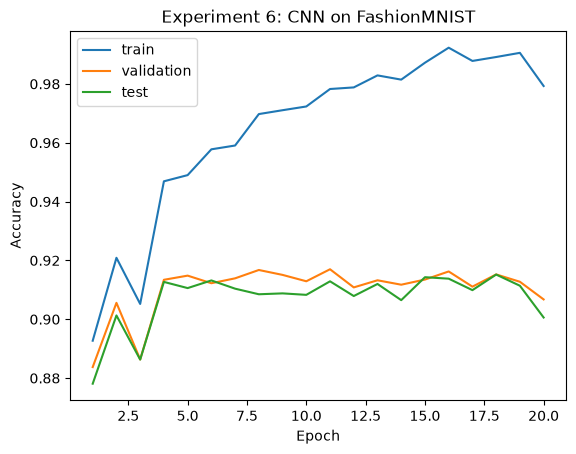

In [ ]:
# Experiment 6: accuracy per epoch
epochs = range(1, EPOCHS + 1)
plt.plot(epochs, train_acc, label="train")
plt.plot(epochs, val_acc, label="validation")
plt.plot(epochs, test_acc, label="test")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Experiment 6: CNN on FashionMNIST")
plt.legend()
plt.show()


In [ ]:
results = {}
results["CNN (Experiment 6)"] = {"test_acc": test_acc[-1], "time_s": train_time, "epochs": EPOCHS}


Model  |  test accuracy  |  training time (s)  |  seconds per epoch
CNN (Experiment 6)  |  0.9006  |  12.1  |  0.61


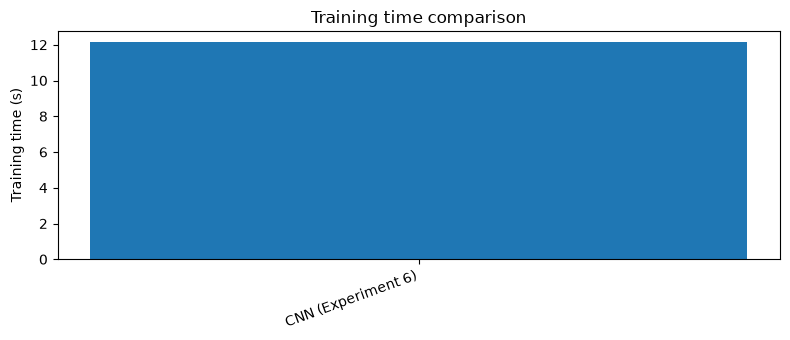

In [ ]:
# Print the results table and draw the training times as a bar chart
def show_results(results):
    print("Model  |  test accuracy  |  training time (s)  |  seconds per epoch")
    for name in results:
        row = results[name]
        print(name, " | ", round(row["test_acc"], 4), " | ", round(row["time_s"], 1),
              " | ", round(row["time_s"] / row["epochs"], 2))

    names = list(results.keys())
    times = [results[name]["time_s"] for name in names]
    plt.figure(figsize=(8, 3.5))
    plt.bar(names, times)
    plt.ylabel("Training time (s)")
    plt.title("Training time comparison")
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.show()

show_results(results)


### Hyperparameter comparison

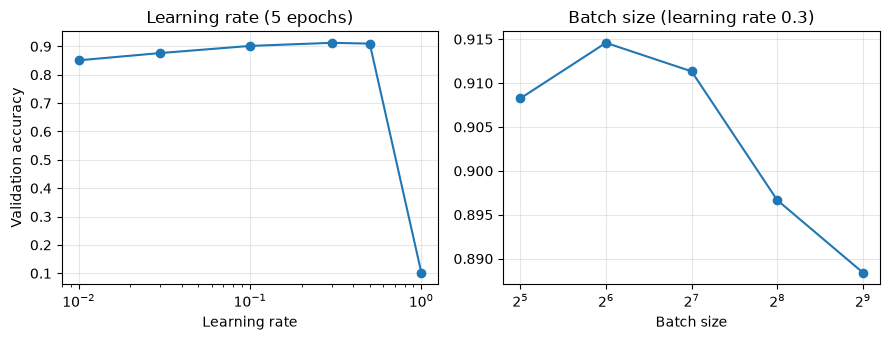

In [ ]:
plt.figure(figsize=(9, 3.5))

plt.subplot(1, 2, 1)
plt.plot(list(lr_table.keys()), list(lr_table.values()), marker="o")
plt.xscale("log")
plt.xlabel("Learning rate")
plt.ylabel("Validation accuracy")
plt.title("Learning rate (5 epochs)")
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(list(bs_table.keys()), list(bs_table.values()), marker="o")
plt.xscale("log", base=2)
plt.xlabel("Batch size")
plt.title("Batch size (learning rate " + str(BEST_LR) + ")")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


## Experiment 7: Data augmentation

Apply random horizontal flips and rotations of up to 10 degrees. These settings match Experiment 5; the tensor-based implementation differs from the MLP image transforms.

augmented range: -0.811 to 2.023
original range:  -0.811 to 2.023
epoch 1   train 0.8692   validation 0.8652   test 0.8554
epoch 2   train 0.8939   validation 0.8884   test 0.8797
epoch 3   train 0.8889   validation 0.881   test 0.8748
epoch 4   train 0.913   validation 0.8979   test 0.8968
epoch 5   train 0.9174   validation 0.9004   test 0.8979
epoch 6   train 0.9223   validation 0.9084   test 0.9004
epoch 7   train 0.9222   validation 0.9034   test 0.9006
epoch 8   train 0.9316   validation 0.9156   test 0.9086
epoch 9   train 0.9276   validation 0.9046   test 0.9025
epoch 10   train 0.937   validation 0.9112   test 0.9127
epoch 11   train 0.9426   validation 0.9159   test 0.9175
epoch 12   train 0.9387   validation 0.9108   test 0.9109
epoch 13   train 0.9372   validation 0.9078   test 0.9047
epoch 14   train 0.9382   validation 0.9087   test 0.9091
epoch 15   train 0.9469   validation 0.9171   test 0.9101
epoch 16   train 0.9489   validation 0.9181   test 0.914
epoch 17   train 0.

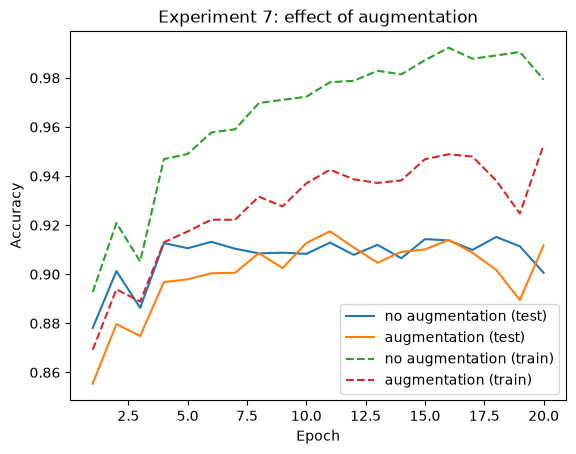

In [ ]:
mean_value = float(mean)
std_value = float(std) + 1e-8

def augment_gpu(images, max_degrees=10):
    n = images.shape[0]
    pixels = images * std_value + mean_value # undo the normalization (back to 0-255 pixels)

    # random horizontal flip
    flip = torch.rand(n, device=images.device) < 0.5 # True for about half of the images
    flipped = pixels.flip(3) # mirror left-right
    pixels = torch.where(flip.view(n, 1, 1, 1), flipped, pixels)

    # random rotation: build one 2x3 rotation matrix per image and apply it
    angles = (torch.rand(n, device=images.device) * 2 - 1) * max_degrees * math.pi / 180 # in rad
    rotation = torch.zeros(n, 2, 3, device=images.device)
    rotation[:, 0, 0] = torch.cos(angles)
    rotation[:, 0, 1] = -torch.sin(angles)
    rotation[:, 1, 0] = torch.sin(angles)
    rotation[:, 1, 1] = torch.cos(angles)
    grid = F.affine_grid(rotation, pixels.shape, align_corners=False)
    pixels = F.grid_sample(pixels, grid, mode="nearest", padding_mode="zeros", align_corners=False) # corners become black

    return (pixels - mean_value) / std_value # normalize again

check = augment_gpu(X_train[:8])
print("augmented range:", round(check.min().item(), 3), "to", round(check.max().item(), 3))
print("original range: ", round(X_train.min().item(), 3), "to", round(X_train.max().item(), 3))

# Experiment 7: train with augmentation
aug_train, aug_val, aug_test, aug_time = train(BEST_LR, BEST_BS, EPOCHS, augment=augment_gpu, verbose=True)
print()
print("Experiment 7 CNN with augmentation")
print("  test accuracy:", round(aug_test[-1], 4))
print("  training time:", round(aug_time, 1), "seconds (", round(aug_time / EPOCHS, 2), "seconds per epoch )")

# plot: with and without augmentation (solid = test, dashed = train)
epochs = range(1, EPOCHS + 1)
plt.plot(epochs, test_acc, label="no augmentation (test)")
plt.plot(epochs, aug_test, label="augmentation (test)")
plt.plot(epochs, train_acc, "--", label="no augmentation (train)")
plt.plot(epochs, aug_train, "--", label="augmentation (train)")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Experiment 7: effect of augmentation")
plt.legend()
plt.show()

results["CNN + augmentation (Experiment 7)"] = {"test_acc": aug_test[-1], "time_s": aug_time, "epochs": EPOCHS}


### Experiment 7.1: Five-seed comparison

Repeat the baseline and augmented CNN experiments with seeds 0–4. Report mean test accuracy and standard deviation.

In [ ]:
def multi_seed(n=5, augment=None):
    """Trains n models with seeds 0, 1, ..., n-1.
    Returns the mean test accuracy, its standard deviation, and the mean training time."""
    accuracies = []
    times = []
    for seed in range(n):
        tr, va, te, seconds = train(BEST_LR, BEST_BS, EPOCHS, seed=seed, augment=augment)
        accuracies.append(te[-1])
        times.append(seconds)
    return np.mean(accuracies), np.std(accuracies), np.mean(times)

base_mean, base_std, base_time = multi_seed()
aug_mean, aug_std, aug_time_mean = multi_seed(augment=augment_gpu)

print("no augmentation:", round(base_mean, 4), "+/-", round(base_std, 4), " (", round(base_time, 1), "seconds )")
print("augmentation:   ", round(aug_mean, 4), "+/-", round(aug_std, 4), " (", round(aug_time_mean, 1), "seconds )")

results["CNN, mean of 5 seeds"] = {"test_acc": base_mean, "time_s": base_time, "epochs": EPOCHS}
results["CNN + aug, mean of 5 seeds"] = {"test_acc": aug_mean, "time_s": aug_time_mean, "epochs": EPOCHS}


no augmentation: 0.9044 +/- 0.003  ( 11.9 seconds )
augmentation:    0.909 +/- 0.0033  ( 18.2 seconds )


## Experiment 8: Frozen ResNet18

Use ImageNet-pretrained ResNet18 with frozen backbone parameters and a replacement classifier. Convert Fashion-MNIST images to three channels, resize to 64 × 64, and train the classifier with augmentation. The model remains in evaluation mode, including its BatchNorm layers.

In [ ]:
def augment(images, max_degrees=10):
    n = images.shape[0]

    # random horizontal flip
    flip = torch.rand(n, device=device) < 0.5
    flipped = images.flip(3)
    images = torch.where(flip.view(n, 1, 1, 1), flipped, images)

    # random rotation
    angles = (torch.rand(n, device=device) * 2 - 1) * max_degrees * math.pi / 180
    rotation = torch.zeros(n, 2, 3, device=device)
    rotation[:, 0, 0] = torch.cos(angles)
    rotation[:, 0, 1] = -torch.sin(angles)
    rotation[:, 1, 0] = torch.sin(angles)
    rotation[:, 1, 1] = torch.cos(angles)
    grid = F.affine_grid(rotation, images.shape, align_corners=False)
    return F.grid_sample(images, grid, mode="nearest", align_corners=False)

# ResNet needs colour images
def to_resnet_images(images):
    images = (images * std_value + mean_value) / 255.0 # undo the normalization
    images = F.interpolate(images, size=(64, 64), mode="bilinear", align_corners=False)
    images = images.repeat(1, 3, 1, 1) # copy the grey channel 3 times
    return images

# convert the whole dataset once
FASHION64 = (to_resnet_images(X_train), y_train,
             to_resnet_images(X_val), y_val,
             to_resnet_images(X_test), y_test)


def pretrained(n_fc):
    resnet = torchvision.models.resnet18(weights="DEFAULT")
    for p in resnet.parameters():
        p.requires_grad = False # freeze

    new_layers = []
    size = 512
    for i in range(n_fc):
        new_layers.append(nn.Linear(size, 256))
        new_layers.append(nn.ReLU())
        size = 256
    new_layers.append(nn.Linear(size, 10))
    resnet.fc = nn.Sequential(*new_layers) # the new layers (the only part that trains)

    imagenet_normalize = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    model = nn.Sequential(imagenet_normalize, resnet)
    return model.to(device).eval()


def count_trainable(model):
    total = 0
    for p in model.parameters():
        if p.requires_grad:
            total += p.numel()
    return total


In [ ]:
def make_pretrained_1fc():
    return pretrained(1)

pt_lr_table = {}
for lr in [0.3, 0.1, 0.03, 0.01]:
    tr, va, te, seconds = train(lr, BEST_BS, 3, augment=augment, data=FASHION64, make=make_pretrained_1fc)
    pt_lr_table[lr] = va[-1]
    print("learning rate", lr, "-> validation accuracy", round(va[-1], 4), " (", round(seconds, 1), "seconds )")

PT_LR = best_setting(pt_lr_table)
print("best learning rate for the new layers:", PT_LR)


learning rate 0.3 -> validation accuracy 0.0968  ( 6.6 seconds )
learning rate 0.1 -> validation accuracy 0.8632  ( 6.4 seconds )
learning rate 0.03 -> validation accuracy 0.8575  ( 6.4 seconds )
learning rate 0.01 -> validation accuracy 0.8476  ( 6.5 seconds )
best learning rate for the new layers: 0.1


### Experiment 8.1: Classifier depth

0 hidden layers:  best validation 0.8568  test 0.8146  time 20.8 s  trainable parameters 5130
1 hidden layers:  best validation 0.8838  test 0.8803  time 21.1 s  trainable parameters 133898
2 hidden layers:  best validation 0.8823  test 0.8789  time 21.8 s  trainable parameters 199690
3 hidden layers:  best validation 0.8811  test 0.8814  time 22.2 s  trainable parameters 265482


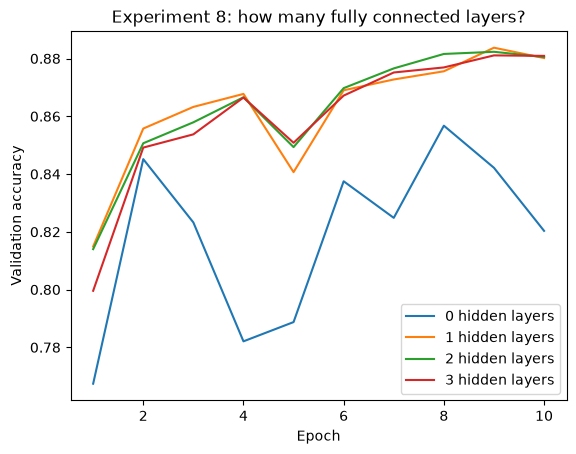

Chosen: 1 hidden layer(s)


In [ ]:
PT_EPOCHS = 10
fc_runs = {}
fc_best_val = {}

for n_fc in [0, 1, 2, 3]:
    def make_this_model():
        return pretrained(n_fc)

    tr, va, te, seconds = train(PT_LR, BEST_BS, PT_EPOCHS, augment=augment, data=FASHION64, make=make_this_model)
    fc_runs[n_fc] = (tr, va, te, seconds)
    fc_best_val[n_fc] = max(va)

    print(n_fc, "hidden layers:",
          " best validation", round(max(va), 4),
          " test", round(te[-1], 4),
          " time", round(seconds, 1), "s",
          " trainable parameters", count_trainable(pretrained(n_fc)))
    plt.plot(range(1, PT_EPOCHS + 1), va, label=str(n_fc) + " hidden layers")

plt.xlabel("Epoch")
plt.ylabel("Validation accuracy")
plt.title("Experiment 8: how many fully connected layers?")
plt.legend()
plt.show()

BEST_NFC = best_setting(fc_best_val)
print("Chosen:", BEST_NFC, "hidden layer(s)")


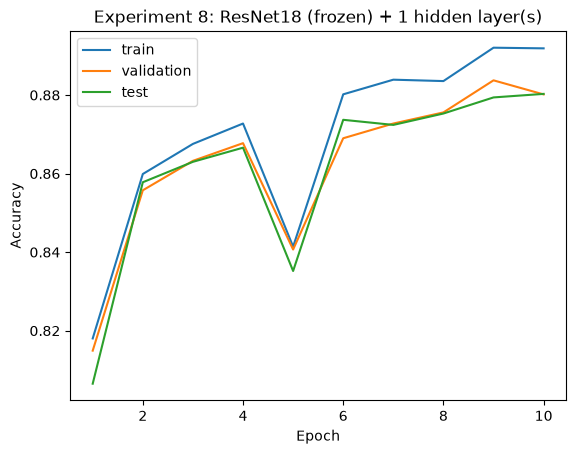

Model  |  test accuracy  |  training time (s)  |  seconds per epoch
CNN (Experiment 6)  |  0.9006  |  12.1  |  0.61
CNN + augmentation (Experiment 7)  |  0.9118  |  19.6  |  0.98
CNN, mean of 5 seeds  |  0.9044  |  11.9  |  0.6
CNN + aug, mean of 5 seeds  |  0.909  |  18.2  |  0.91
ResNet18 frozen + 1 FC (Experiment 8)  |  0.8803  |  21.1  |  2.11
Best MLP, Experiment 5 (L1 + augmentation)  |  0.8782  |  438.1  |  21.91


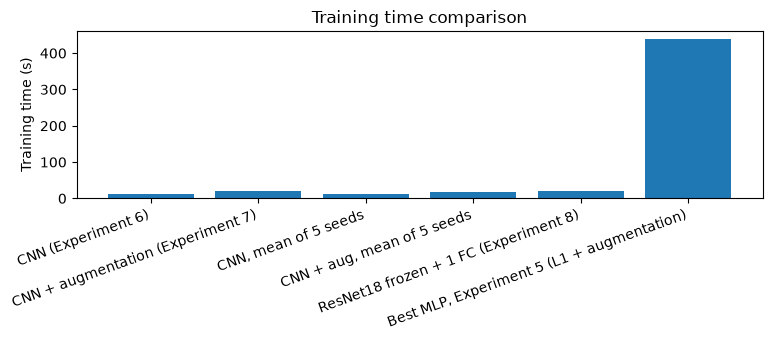

In [ ]:
# Experiment 8: the chosen pre-trained model, accuracy per epoch
pre_train, pre_val, pre_test, pre_time = fc_runs[BEST_NFC]

epochs = range(1, PT_EPOCHS + 1)
plt.plot(epochs, pre_train, label="train")
plt.plot(epochs, pre_val, label="validation")
plt.plot(epochs, pre_test, label="test")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Experiment 8: ResNet18 (frozen) + " + str(BEST_NFC) + " hidden layer(s)")
plt.legend()
plt.show()

results["ResNet18 frozen + " + str(BEST_NFC) + " FC (Experiment 8)"] = {"test_acc": pre_test[-1], "time_s": pre_time, "epochs": PT_EPOCHS}
# Best Experiment 5 MLP (L1 + augmentation). Numbers from the other notebook:
# test accuracy 0.8782, training time 438.1 s for 20 epochs (NumPy on the CPU, measured without the per-epoch accuracy check)
results["Best MLP, Experiment 5 (L1 + augmentation)"] = {"test_acc": 0.8782, "time_s": 438.1, "epochs": 20}
show_results(results)


## Experiment 9: Transfer learning on CIFAR-10

Compare the frozen ResNet18 classifier with a CNN trained from scratch on CIFAR-10, using 40,000 training, 10,000 validation, and 10,000 test images.

In [ ]:
cifar_train = datasets.CIFAR10(root='./data', train=True, download=True)
cifar_test = datasets.CIFAR10(root='./data', train=False, download=True)

def cifar_tensors(dataset):
    images = torch.tensor(dataset.data) # shape (N, 32, 32, 3)
    images = images.permute(0, 3, 1, 2)
    images = images.float() / 255.0
    labels = torch.tensor(dataset.targets)
    return images.to(device), labels.to(device)

Xc, yc = cifar_tensors(cifar_train)
Xc_test, yc_test = cifar_tensors(cifar_test)

order = np.random.default_rng(551).permutation(len(Xc))
order = torch.from_numpy(order).to(device)
Xc = Xc[order]
yc = yc[order]

CIFAR32 = (Xc[:40000], yc[:40000], Xc[40000:], yc[40000:], Xc_test, yc_test)

def resize_to_64(images):
    return F.interpolate(images, size=(64, 64), mode="bilinear", align_corners=False)

CIFAR64 = (resize_to_64(Xc[:40000]), yc[:40000],
           resize_to_64(Xc[40000:]), yc[40000:],
           resize_to_64(Xc_test), yc_test)
print("CIFAR-10 train:", CIFAR32[0].shape, " validation:", CIFAR32[2].shape, " test:", CIFAR32[4].shape)


CIFAR-10 train: torch.Size([40000, 3, 32, 32])  validation: torch.Size([10000, 3, 32, 32])  test: torch.Size([10000, 3, 32, 32])


In [ ]:
# Pre-trained ResNet18 on CIFAR-10, with the same number of layers and learning rate as Experiment 8
def make_best_pretrained():
    return pretrained(BEST_NFC)

cifar_pre_train, cifar_pre_val, cifar_pre_test, cifar_pre_time = train(
    PT_LR, BEST_BS, PT_EPOCHS, augment=augment, data=CIFAR64, make=make_best_pretrained, verbose=True)


def cnn_rgb():
    model = nn.Sequential(
        nn.Conv2d(3, 32, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Conv2d(32, 64, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Flatten(),
        nn.Linear(64 * 8 * 8, 256),
        nn.ReLU(),
        nn.Linear(256, 10),
    )
    return model.to(device)

# its own learning rate, chosen by validation accuracy (3 epochs each)
cifar_lr_table = {}
for lr in [0.3, 0.1, 0.03]:
    tr, va, te, seconds = train(lr, BEST_BS, 3, augment=augment, data=CIFAR32, make=cnn_rgb)
    cifar_lr_table[lr] = va[-1]
    print("CIFAR CNN, learning rate", lr, "-> validation accuracy", round(va[-1], 4))
CIFAR_LR = best_setting(cifar_lr_table)

cifar_cnn_train, cifar_cnn_val, cifar_cnn_test, cifar_cnn_time = train(
    CIFAR_LR, BEST_BS, EPOCHS, augment=augment, data=CIFAR32, make=cnn_rgb)


epoch 1   train 0.6811   validation 0.6797   test 0.6736
epoch 2   train 0.7136   validation 0.6999   test 0.6965
epoch 3   train 0.7326   validation 0.7227   test 0.7128
epoch 4   train 0.7535   validation 0.7372   test 0.7312
epoch 5   train 0.7501   validation 0.7322   test 0.7296
epoch 6   train 0.7486   validation 0.7242   test 0.7251
epoch 7   train 0.7645   validation 0.7464   test 0.7367
epoch 8   train 0.7461   validation 0.7201   test 0.7203
epoch 9   train 0.7698   validation 0.738   test 0.7399
epoch 10   train 0.7823   validation 0.7533   test 0.7522
CIFAR CNN, learning rate 0.3 -> validation accuracy 0.5786
CIFAR CNN, learning rate 0.1 -> validation accuracy 0.5702
CIFAR CNN, learning rate 0.03 -> validation accuracy 0.4844


Test accuracy           FashionMNIST   CIFAR-10
Pre-trained ResNet18:   0.8803         0.7522
CNN from scratch:       0.9118         0.6712


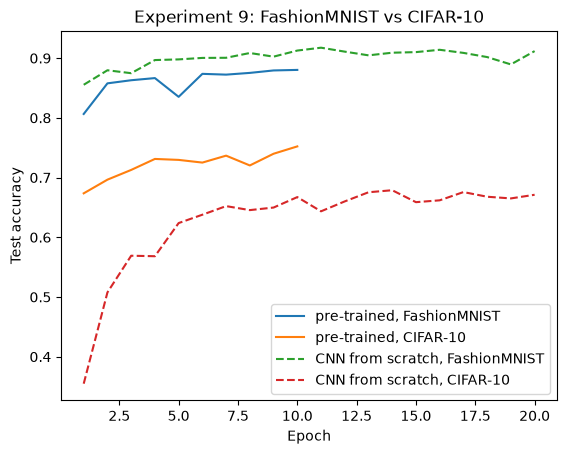

In [ ]:
# Experiment 9: compare the two datasets
print("Test accuracy           FashionMNIST   CIFAR-10")
print("Pre-trained ResNet18:  ", round(pre_test[-1], 4), "       ", round(cifar_pre_test[-1], 4))
print("CNN from scratch:      ", round(aug_test[-1], 4), "       ", round(cifar_cnn_test[-1], 4))

plt.plot(range(1, PT_EPOCHS + 1), pre_test, label="pre-trained, FashionMNIST")
plt.plot(range(1, PT_EPOCHS + 1), cifar_pre_test, label="pre-trained, CIFAR-10")
plt.plot(range(1, EPOCHS + 1), aug_test, "--", label="CNN from scratch, FashionMNIST")
plt.plot(range(1, EPOCHS + 1), cifar_cnn_test, "--", label="CNN from scratch, CIFAR-10")
plt.xlabel("Epoch")
plt.ylabel("Test accuracy")
plt.title("Experiment 9: FashionMNIST vs CIFAR-10")
plt.legend()
plt.show()

results["ResNet18 frozen + " + str(BEST_NFC) + " FC, CIFAR-10 (Experiment 9)"] = {"test_acc": cifar_pre_test[-1], "time_s": cifar_pre_time, "epochs": PT_EPOCHS}
results["CNN from scratch, CIFAR-10 (Experiment 9)"] = {"test_acc": cifar_cnn_test[-1], "time_s": cifar_cnn_time, "epochs": EPOCHS}


### Experiment 9.1: Augmentation across datasets

Compare frozen ResNet18 with and without augmentation on Fashion-MNIST and CIFAR-10.

Pre-trained ResNet18, test accuracy    FashionMNIST   CIFAR-10
with augmentation:                     0.8803         0.7522
without augmentation:                  0.8885         0.7615

Train - test gap (bigger = more overfitting)
FashionMNIST  with augmentation: 0.0116   without: 0.0345
CIFAR-10      with augmentation: 0.0301   without: 0.1344

Training time (s)   with augmentation   without
FashionMNIST:       21.1                19.7
CIFAR-10:           17.7                16.1


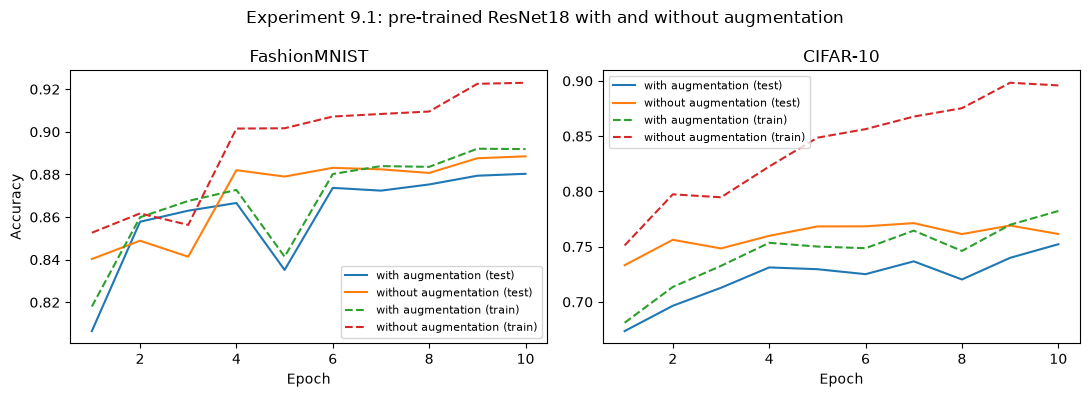

In [ ]:
fashion_noaug_train, fashion_noaug_val, fashion_noaug_test, fashion_noaug_time = train(
    PT_LR, BEST_BS, PT_EPOCHS, data=FASHION64, make=make_best_pretrained)
cifar_noaug_train, cifar_noaug_val, cifar_noaug_test, cifar_noaug_time = train(
    PT_LR, BEST_BS, PT_EPOCHS, data=CIFAR64, make=make_best_pretrained)

print("Pre-trained ResNet18, test accuracy    FashionMNIST   CIFAR-10")
print("with augmentation:                    ", round(pre_test[-1], 4), "       ", round(cifar_pre_test[-1], 4))
print("without augmentation:                 ", round(fashion_noaug_test[-1], 4), "       ", round(cifar_noaug_test[-1], 4))
print()

print("Train - test gap (bigger = more overfitting)")

print("FashionMNIST  with augmentation:", round(pre_train[-1] - pre_test[-1], 4),
      "  without:", round(fashion_noaug_train[-1] - fashion_noaug_test[-1], 4))

print("CIFAR-10      with augmentation:", round(cifar_pre_train[-1] - cifar_pre_test[-1], 4),
      "  without:", round(cifar_noaug_train[-1] - cifar_noaug_test[-1], 4))

print()
print("Training time (s)   with augmentation   without")

print("FashionMNIST:      ", round(pre_time, 1), "              ", round(fashion_noaug_time, 1))

print("CIFAR-10:          ", round(cifar_pre_time, 1), "              ", round(cifar_noaug_time, 1))

epochs = range(1, PT_EPOCHS + 1)
plt.figure(figsize=(11, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs, pre_test, label="with augmentation (test)")
plt.plot(epochs, fashion_noaug_test, label="without augmentation (test)")
plt.plot(epochs, pre_train, "--", label="with augmentation (train)")
plt.plot(epochs, fashion_noaug_train, "--", label="without augmentation (train)")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("FashionMNIST")
plt.legend(fontsize=8)

plt.subplot(1, 2, 2)
plt.plot(epochs, cifar_pre_test, label="with augmentation (test)")
plt.plot(epochs, cifar_noaug_test, label="without augmentation (test)")
plt.plot(epochs, cifar_pre_train, "--", label="with augmentation (train)")
plt.plot(epochs, cifar_noaug_train, "--", label="without augmentation (train)")
plt.xlabel("Epoch")
plt.title("CIFAR-10")
plt.legend(fontsize=8)

plt.suptitle("Experiment 9.1: pre-trained ResNet18 with and without augmentation")
plt.tight_layout()
plt.show()

results["ResNet18 frozen, no augmentation, FashionMNIST (Experiment 9.1)"] = {"test_acc": fashion_noaug_test[-1], "time_s": fashion_noaug_time, "epochs": PT_EPOCHS}
results["ResNet18 frozen, no augmentation, CIFAR-10 (Experiment 9.1)"] = {"test_acc": cifar_noaug_test[-1], "time_s": cifar_noaug_time, "epochs": PT_EPOCHS}


## Summary

Accuracy curves appear alongside each experiment. The table below collects the saved results; the MLP comparison is copied from Experiment 5 in the other notebook and represents its best augmented configuration, not its highest saved MLP accuracy overall. Timings come from different CPU/GPU runs and are not a controlled speed comparison.

### Final results

Model  |  test accuracy  |  training time (s)  |  seconds per epoch
CNN (Experiment 6)  |  0.9006  |  12.1  |  0.61
CNN + augmentation (Experiment 7)  |  0.9118  |  19.6  |  0.98
CNN, mean of 5 seeds  |  0.9044  |  11.9  |  0.6
CNN + aug, mean of 5 seeds  |  0.909  |  18.2  |  0.91
ResNet18 frozen + 1 FC (Experiment 8)  |  0.8803  |  21.1  |  2.11
Best MLP, Experiment 5 (L1 + augmentation)  |  0.8782  |  438.1  |  21.91
ResNet18 frozen + 1 FC, CIFAR-10 (Experiment 9)  |  0.7522  |  17.7  |  1.77
CNN from scratch, CIFAR-10 (Experiment 9)  |  0.6712  |  15.7  |  0.78
ResNet18 frozen, no augmentation, FashionMNIST (Experiment 9.1)  |  0.8885  |  19.7  |  1.97
ResNet18 frozen, no augmentation, CIFAR-10 (Experiment 9.1)  |  0.7615  |  16.1  |  1.61


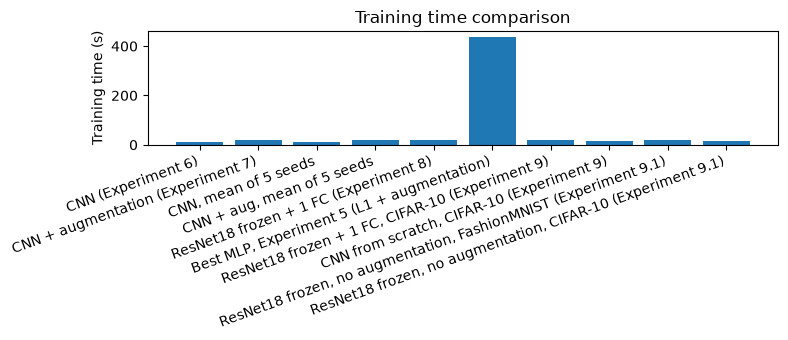

In [ ]:
show_results(results)
